# M2 · 02 — Exploratory Data Analysis

**Project:** MediBridge, which turns Hinglish clinical speech and text into structured English medical entities.
**Dataset:** Eka Medical ASR Evaluation Dataset (EkaCare, MIT licence). See [01_data_card.md](01_data_card.md).

This notebook explores the **raw** data before any cleaning. We want to know what the transcripts look like, how the entity labels are distributed, how much Hindi–English code-mixing there is, and which data-quality issues need cleaning (see `03_data_cleaning.ipynb`).

> Charts use Latin-script labels only, because matplotlib cannot shape Devanagari conjuncts correctly. Devanagari text is shown in tables instead.

In [1]:
# Requires the project package: `pip install -e ".[analysis]"` from the repository root.
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from medibridge.config import ENTITY_TYPES, SUBSETS
from medibridge.io import load_raw
from medibridge.spans import parse_entities
from medibridge.text import code_mixing_index, token_script, tokenize

In [2]:
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
FIG = Path("figures")
FIG.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 160)

## 1. Load the raw data
Two subsets: **`hi`**, Hindi and Hinglish (our primary data), and **`en`**, Indian-English medical speech (auxiliary). The audio column is not loaded, because M2 works on the transcripts and metadata.

In [3]:
raw = {s: load_raw(s) for s in SUBSETS}


def enrich(df):
    df = df.copy()
    df["entities"] = df["medical_entities"].map(parse_entities)
    toks = df["text"].map(lambda t: [x for x, _, _ in tokenize(t)])
    df["n_chars"] = df["text"].str.len()
    df["n_tokens"] = toks.map(len)
    df["n_entities"] = df["entities"].map(len)
    scripts = toks.map(lambda ts: [token_script(t) for t in ts])
    df["pct_devanagari"] = scripts.map(lambda s: s.count("dev") / max(len(s), 1))
    df["pct_latin"] = scripts.map(lambda s: s.count("lat") / max(len(s), 1))
    df["cmi"] = toks.map(code_mixing_index)
    return df


raw = {s: enrich(d) for s, d in raw.items()}
both = pd.concat(raw.values(), ignore_index=True)
raw["hi"].drop(columns=["entities"]).head(3)

,subset,file_name,duration,text,audio_language,text_language,session_id,speaker,type_concept,recording_context,medical_entities,md5_text,md5_audio,n_chars,n_tokens,n_entities,pct_devanagari,pct_latin,cmi
0,hi,/250503/ce-5954386c-da36-4b73-aee3-afd606625d7e/5.m4a,11.264,and उसको daily सुबह शाम में लगाना। And medicines दे रहा हूँ मैं थोड़ा. Augmentin 650 mg.,hi,hi,ce-5954386c-da36-4b73-aee3-afd606625d7e,None,misc_medical,conversation,"[[""daily"", ""advices"", [[9, 14]]], [""\u0938\u0941\u092c\u0939 \u0936\u093e\u092e"", ""advices"", [[15, 23]]], ...",d3da2c3442029925e945c5415b3ba93c,8840f7fe1535fdbfbf0ba059521fc406,88,20,4,0.500000,0.300000,37.500000
1,hi,/250503/ce-5954386c-da36-4b73-aee3-afd606625d7e/4.m4a,11.712,"और ये जो हुआ है आपको, पूरा infection हुआ है. हम्म । And इसके लिए हम लोग medication जो है। हम्म । मैं sunsc...",hi,hi,ce-5954386c-da36-4b73-aee3-afd606625d7e,None,misc_medical,conversation,"[[""infection"", ""clinical_findings"", [[27, 36]]], [""medication"", ""misc_medical"", [[72, 82]]], [""sunscreen"",...",ce76bfddd71d1b37c391dd001d4d07fa,68937db7f3d753452c2678e7b76c35e8,145,36,6,0.666667,0.138889,17.241379
2,hi,/250503/ce-5954386c-da36-4b73-aee3-afd606625d7e/6.m4a,20.736,"daily three times. And और कुछ, दवाई देता हूं और आप एक lab test करा लेना, CBC lab test. हम्म । और chest X r...",hi,hi,ce-5954386c-da36-4b73-aee3-afd606625d7e,None,misc_medical,conversation,"[[""daily three times"", ""advices"", [[0, 17]]], [""lab test"", ""diagnostics"", [[54, 62], [77, 85]]], [""CBC lab...",431d272cfaf2c3c240e3bbac0893d137,9534853379239bd5b12b231f963a41e6,284,76,13,0.434211,0.328947,43.103448


## 2. Dataset overview

In [4]:
overview = (
    both.groupby("subset")
    .agg(
        rows=("text", "size"),
        sessions=("session_id", "nunique"),
        known_speakers=("speaker", "nunique"),
        missing_speaker=("speaker", lambda s: s.isna().sum()),
        audio_hours=("duration", lambda d: round(d.sum() / 3600, 2)),
        entity_spans=("n_entities", "sum"),
    )
    .reindex(["hi", "en"])
)
overview

,rows,sessions,known_speakers,missing_speaker,audio_hours,entity_spans
subset,,,,,,
hi,320,203,5,127,1.57,1897
en,3619,3524,56,110,8.40,11373


In [5]:
pd.crosstab(both["subset"], both["recording_context"], margins=True)

recording_context,conversation,narration_entity,narration_sentence,All
subset,,,,
en,110,2206,1303,3619
hi,127,0,193,320
All,237,2206,1496,3939


Each recording has one of three contexts:
- **`narration_entity`** (en only): a single medical term read aloud, e.g. "facial swelling".
- **`narration_sentence`**: a sentence read aloud. In `hi` these are drug descriptions written in Devanagari.
- **`conversation`**: real doctor–patient talk, which is the most realistic and the most code-mixed.

## 3. Audio duration and transcript length

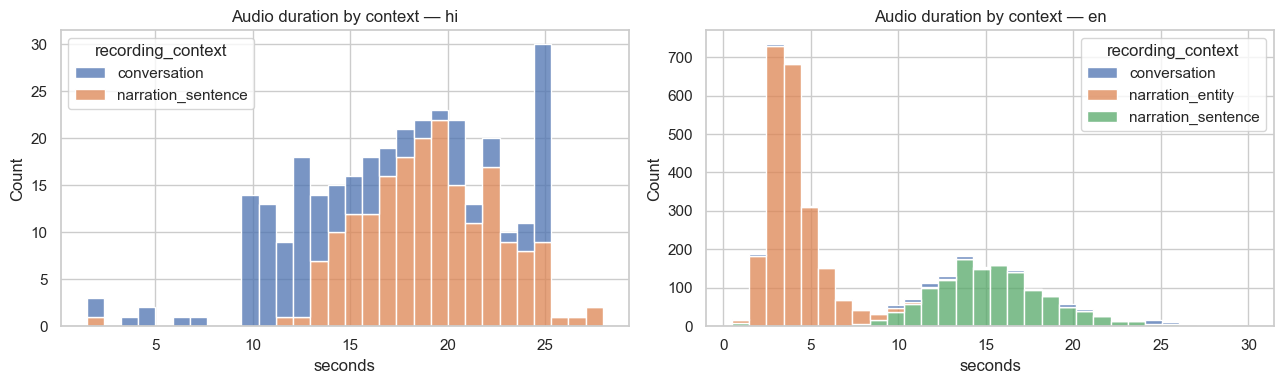

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, s in zip(axes, ("hi", "en")):
    sns.histplot(
        data=raw[s], x="duration", hue="recording_context", bins=30, multiple="stack", ax=ax
    )
    ax.set(title=f"Audio duration by context — {s}", xlabel="seconds")
plt.tight_layout()
plt.savefig(FIG / "01_duration.png", dpi=150)
plt.show()

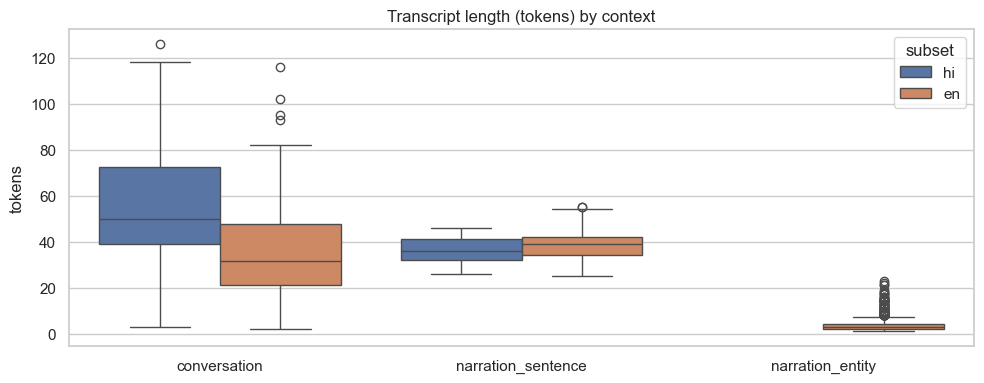

duration  n_tokens  n_chars
subset recording_context                              
en     conversation            13.0      31.5    134.5
       narration_entity         3.7       3.0     18.0
       narration_sentence      15.1      39.0    212.0
hi     conversation            13.4      50.0    208.0
       narration_sentence      19.0      36.0    185.0

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=both, x="recording_context", y="n_tokens", hue="subset", ax=ax)
ax.set(title="Transcript length (tokens) by context", xlabel="", ylabel="tokens")
plt.tight_layout()
plt.savefig(FIG / "02_tokens.png", dpi=150)
plt.show()
both.groupby(["subset", "recording_context"])[["duration", "n_tokens", "n_chars"]].median().round(1)

## 4. Entity labels

In [8]:
spans = pd.DataFrame(
    [
        {"subset": r.subset, "context": r.recording_context, **e}
        for r in both.itertuples()
        for e in r.entities
    ]
)
spans["n_tokens"] = spans["text"].map(lambda t: len(tokenize(t)))
type_counts = pd.crosstab(spans["type"], spans["subset"]).reindex(ENTITY_TYPES)[["hi", "en"]]
type_share = (type_counts / type_counts.sum() * 100).round(1)
pd.concat({"count": type_counts, "% of subset": type_share}, axis=1)

count       % of subset      
subset               hi    en          hi    en
type                                           
drugs               918  2722        48.4  23.9
clinical_findings   679  5951        35.8  52.3
diagnostics         129  1046         6.8   9.2
advices             104   395         5.5   3.5
misc_medical         67  1259         3.5  11.1

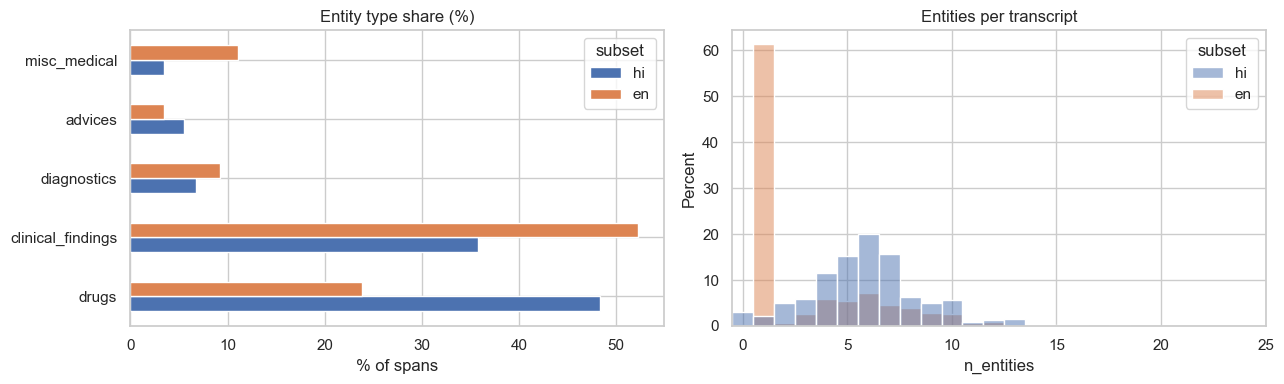

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
type_share.plot.barh(ax=axes[0])
axes[0].set(title="Entity type share (%)", xlabel="% of spans", ylabel="")
sns.histplot(
    data=both,
    x="n_entities",
    hue="subset",
    discrete=True,
    stat="percent",
    common_norm=False,
    ax=axes[1],
)
axes[1].set(title="Entities per transcript", xlim=(-0.5, 25))
plt.tight_layout()
plt.savefig(FIG / "03_entity_types.png", dpi=150)
plt.show()

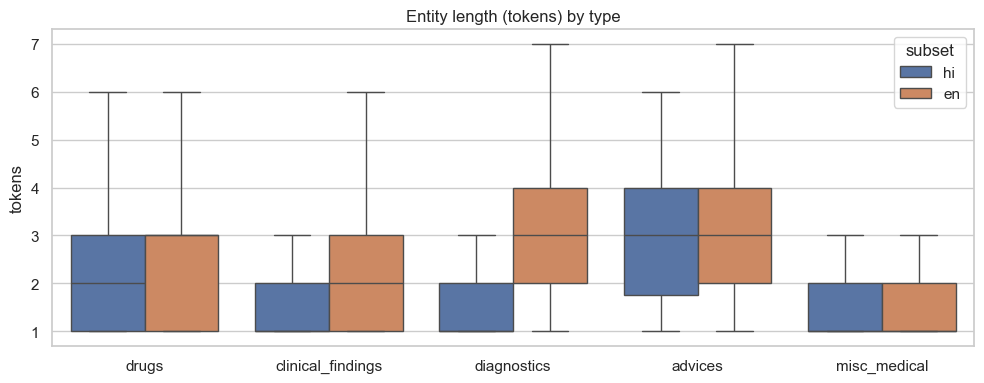

mean  50%   max
subset type                              
en     advices            3.77  3.0  21.0
       clinical_findings  2.26  2.0  23.0
       diagnostics        3.00  3.0  10.0
       drugs              2.86  3.0  15.0
       misc_medical       1.68  1.0   9.0
hi     advices            3.05  3.0   8.0
       clinical_findings  1.82  1.0  13.0
       diagnostics        1.74  1.0   6.0
       drugs              2.07  2.0   8.0
       misc_medical       1.55  1.0   4.0

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(
    data=spans, x="type", y="n_tokens", hue="subset", order=ENTITY_TYPES, ax=ax, showfliers=False
)
ax.set(title="Entity length (tokens) by type", xlabel="", ylabel="tokens")
plt.tight_layout()
plt.savefig(FIG / "04_entity_length.png", dpi=150)
plt.show()
spans.groupby(["subset", "type"])["n_tokens"].describe()[["mean", "50%", "max"]].round(2)

### Most frequent entities per type (Hindi subset)

In [11]:
hi_spans = spans[spans.subset == "hi"]
top = {t: hi_spans[hi_spans.type == t]["text"].value_counts().head(10) for t in ENTITY_TYPES}
pd.DataFrame(
    {t: [f"{k} ({v})" for k, v in top[t].items()] + [""] * (10 - len(top[t])) for t in ENTITY_TYPES}
)

,drugs,clinical_findings,diagnostics,advices,misc_medical
0,टैबलेट (17),डायबिटीज (35),एचबीए१सी (9),दिन में दो बार (5),दो लीटर (4)
1,कैल्शियम (16),हाई ब्लड प्रेशर (15),एचबीएवनसी (7),after food (4),पोलन (3)
2,मेटफॉर्मिन (14),दर्द (15),वाइटल्स (7),पानी (4),ट्रीटमेंट (2)
3,कोलिकैल्सीफेरोल (14),फीवर (12),अल्ट्रासाउंड (6),हाइड्रेशन (3),सिगरेट (2)
4,विटामिन डी3 (12),बीपी (10),टेम्परेचर (6),लो-फैट डाइट (3),न्यूरोलॉजी (2)
5,एंटीबायोटिक (9),ब्लड प्रेशर (10),examine (4),खाने के बाद (2),सिम्पटम्स (2)
6,स्ट्रिप (8),बुखार (9),pulse (4),rest (2),Oily food (2)
7,टैबलेट्स (8),एलर्जी (9),पीआरपी (4),डॉक्टर के निर्देशानुसार लेना (2),smoking (2)
8,10 टैबलेट (8),इन्फेक्शन (8),एफबीएस (3),जीवनशैली में बदलाव (2),drink alcohol (2)
9,डाइक्लोफेनेक (7),बैक्टीरियल इन्फेक्शन (8),पीपीबीएस (3),एक्सरसाइज (2),तीन से चार लीटर (2)


In [12]:
en_spans = spans[spans.subset == "en"]
pd.DataFrame(
    {
        t: [
            f"{k} ({v})"
            for k, v in en_spans[en_spans.type == t]["text"].value_counts().head(8).items()
        ]
        for t in ENTITY_TYPES
    }
)

,drugs,clinical_findings,diagnostics,advices,misc_medical
0,antibiotic (78),pain (185),blood sugar (23),three times a day (17),skin (40)
1,statins (28),blood pressure (103),CT (13),3 times a day (8),throat (36)
2,alcohol (24),high blood pressure (100),MRI (10),5 days (6),blood (29)
3,penicillin (23),swelling (87),X-ray (8),five days (5),heart (26)
4,antifungals (19),diabetes (76),physical examination (6),with or without food (5),lungs (25)
5,anti-diabetic drugs (18),infections (66),blood sugar levels (5),6 days (5),ear (22)
6,amlodipine (15),bacterial infections (63),CT scan (5),diet (5),nose (22)
7,Phenobarbital (14),type 2 diabetes mellitus (57),blood pressure (4),exercise (5),blood vessels (20)


## 5. Code-mixing: how much Hindi and English is mixed?
Each token is tagged by **script**: Devanagari, Latin, number, or other. The **Code-Mixing Index** (CMI; Das & Gambäck, 2014) is 0 for monolingual text and rises towards 50 as two languages are mixed equally.

In [13]:
hi = raw["hi"]
script_mix = (
    hi.groupby("recording_context")[["pct_devanagari", "pct_latin"]].mean().mul(100).round(1)
)
script_mix["rows_with_any_latin_%"] = (
    hi.groupby("recording_context")["pct_latin"].apply(lambda s: (s > 0).mean() * 100).round(1)
)
script_mix["mean_CMI"] = hi.groupby("recording_context")["cmi"].mean().round(2)
script_mix

,pct_devanagari,pct_latin,rows_with_any_latin_%,mean_CMI
recording_context,,,,
conversation,77.3,5.9,19.7,6.12
narration_sentence,87.2,0.2,5.2,0.20


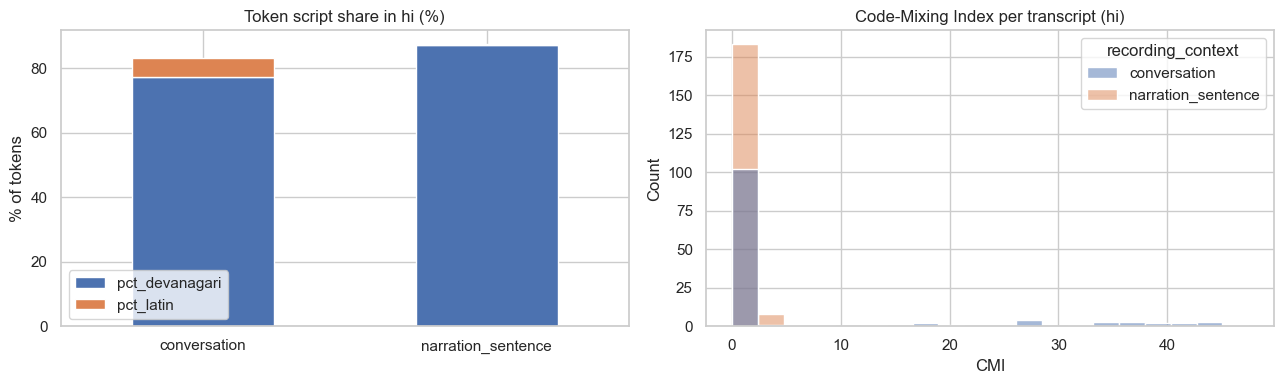

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
script_mix[["pct_devanagari", "pct_latin"]].plot.bar(stacked=True, ax=axes[0], rot=0)
axes[0].set(title="Token script share in hi (%)", ylabel="% of tokens", xlabel="")
sns.histplot(data=hi, x="cmi", hue="recording_context", bins=20, ax=axes[1])
axes[1].set(title="Code-Mixing Index per transcript (hi)", xlabel="CMI")
plt.tight_layout()
plt.savefig(FIG / "05_code_mixing.png", dpi=150)
plt.show()

### Hidden code-mixing: English medical words written in Devanagari
The narration sentences are almost entirely in Devanagari, yet most of their medical words are **English words transliterated into Devanagari** (e.g. इन्फेक्शन = *infection*, एंटीफंगल = *antifungal*). Measuring by script alone underestimates the mixing. This is a key input for translation in M3: the model must recognise English loanwords in Devanagari.

In [15]:
hi_spans = hi_spans.assign(
    script=hi_spans["text"].map(
        lambda t: "Devanagari" if re.search("[\u0900-\u097f]", t) else "Latin"
    )
)
display(pd.crosstab(hi_spans["context"], hi_spans["script"], margins=True))
hi_spans[hi_spans.script == "Devanagari"].query("type in ['drugs','clinical_findings']")[
    "text"
].value_counts().head(15).rename("count").to_frame()

script,Devanagari,Latin,All
context,,,
conversation,558,131,689
narration_sentence,1208,0,1208
All,1766,131,1897


,count
text,
डायबिटीज,35
टैबलेट,17
कैल्शियम,16
दर्द,15
हाई ब्लड प्रेशर,15
मेटफॉर्मिन,14
कोलिकैल्सीफेरोल,14
विटामिन डी3,12
फीवर,12


## 6. Dosage patterns and conversational fillers

In [16]:
unit_patterns = {
    "mg (Latin)": r"\bmg\b",
    "ml (Latin)": r"\bml\b",
    "% (any)": r"%",
    "एमजी (mg in Devanagari)": r"एमजी",
    "एमएल (ml in Devanagari)": r"एमएल",
    "tablet / टैबलेट": r"(?i)tablet|टैबलेट",
    "daily / रोज": r"(?i)daily|रोज",
}
pd.DataFrame(
    {
        s: {k: int(raw[s]["text"].str.count(p).sum()) for k, p in unit_patterns.items()}
        for s in SUBSETS
    }
)

,hi,en
mg (Latin),3,123
ml (Latin),2,4
% (any),12,55
एमजी (mg in Devanagari),132,0
एमएल (ml in Devanagari),18,0
tablet / टैबलेट,152,1003
daily / रोज,23,17


In [17]:
fillers = {
    "हम्म": r"हम्म",
    "okay / ओके": r"(?i)\bokay\b|ओके",
    "अह / umm": r"\bअह\b|(?i)\bumm?\b",
    "हाँ / हां": r"हाँ|हां",
}
conv = hi[hi.recording_context == "conversation"]
pd.Series(
    {k: int(conv["text"].str.count(p).sum()) for k, p in fillers.items()},
    name="count in hi conversations",
).to_frame()

,count in hi conversations
हम्म,6
okay / ओके,83
अह / umm,2
हाँ / हां,39


## 7. Data-quality issues found (input to cleaning)

In [18]:
def overlaps(ents):
    n = 0
    for i, a in enumerate(ents):
        for b in ents[i + 1 :]:
            n += a["start"] < b["end"] and b["start"] < a["end"]
    return n


quality = pd.DataFrame(
    {
        s: {
            "rows": len(d),
            "duplicate transcripts (md5_text)": int(d["md5_text"].duplicated().sum()),
            "duplicate audio (md5_audio)": int(d["md5_audio"].duplicated().sum()),
            "rows with no entities": int((d["n_entities"] == 0).sum()),
            "missing speaker id": int(d["speaker"].isna().sum()),
            "audio shorter than 1 s": int((d["duration"] < 1).sum()),
            "overlapping / nested span pairs": int(d["entities"].map(overlaps).sum()),
            "entity offsets that do not match text": int(
                sum(
                    t[e["start"] : e["end"]] != e["text"]
                    for t, es in zip(d.text, d.entities)
                    for e in es
                )
            ),
            "texts with double spaces / zero-width chars": int(
                d["text"].str.contains("  |\u200b|\ufeff").sum()
            ),
        }
        for s, d in raw.items()
    }
)
quality

,hi,en
rows,320,3619
duplicate transcripts (md5_text),4,265
duplicate audio (md5_audio),1,1
rows with no entities,10,10
missing speaker id,127,110
audio shorter than 1 s,0,8
overlapping / nested span pairs,162,643
entity offsets that do not match text,0,0
texts with double spaces / zero-width chars,0,33


## 8. Representative examples

In [19]:
for ctx, g in raw["hi"].groupby("recording_context"):
    r = g.iloc[2]
    print(f"--- hi / {ctx} ---\n{r.text[:300]}")
    print("entities:", [(e["text"], e["type"]) for e in r.entities][:8], "\n")
for ctx, g in raw["en"].groupby("recording_context"):
    r = g.iloc[1]
    print(
        f"--- en / {ctx} ---\n{r.text[:200]}\nentities:",
        [(e["text"], e["type"]) for e in r.entities][:6],
        "\n",
    )

--- hi / conversation ---
daily three times. And और कुछ, दवाई देता हूं और आप एक lab test करा लेना, CBC lab test. हम्म । और chest X ray करा लेना। हम्म हम्म । And कोई fever, viral fever है आपको? नहीं। नहीं है viral fever. खांसी वगैरह ऐसा कुछ है? No. Okay, ठीक है, आपका जो follow-up रहेगा, after eight days रहेगा।
entities: [('daily three times', 'advices'), ('lab test', 'diagnostics'), ('CBC lab test', 'diagnostics'), ('lab test', 'diagnostics'), ('chest X ray', 'diagnostics'), ('fever', 'clinical_findings'), ('viral fever', 'clinical_findings'), ('fever', 'clinical_findings')] 

--- hi / narration_sentence ---
बीटाडीन 5 % विवरण बीटाडीन ऑइंटमेंट एक टॉपिकल एंटीसेप्टिक है जिसका इस्तेमाल मामूली घावों या कटों में इन्फेक्शन के इलाज और रोकथाम के लिए किया जाता है।
entities: [('बीटाडीन 5 %', 'drugs'), ('बीटाडीन ऑइंटमेंट', 'drugs'), ('टॉपिकल एंटीसेप्टिक', 'drugs'), ('घावों', 'clinical_findings'), ('कटों', 'clinical_findings'), ('इन्फेक्शन', 'clinical_findings')] 

--- en / conversation ---
2 times 

In [20]:
key = {
    "hi_rows": len(raw["hi"]),
    "en_rows": len(raw["en"]),
    "hi_audio_hours": round(raw["hi"].duration.sum() / 3600, 2),
    "en_audio_hours": round(raw["en"].duration.sum() / 3600, 2),
    "hi_entity_spans": int(raw["hi"].n_entities.sum()),
    "en_entity_spans": int(raw["en"].n_entities.sum()),
    "hi_conversation_rows_with_latin_%": float(
        script_mix.loc["conversation", "rows_with_any_latin_%"]
    ),
    "hi_entities_in_devanagari_%": round((hi_spans.script == "Devanagari").mean() * 100, 1),
}
key

{'hi_rows': 320,
 'en_rows': 3619,
 'hi_audio_hours': np.float64(1.57),
 'en_audio_hours': np.float64(8.4),
 'hi_entity_spans': 1897,
 'en_entity_spans': 11373,
 'hi_conversation_rows_with_latin_%': 19.7,
 'hi_entities_in_devanagari_%': np.float64(93.1)}

## Key findings
1. **Size:** `hi` has 320 transcripts (1.57 h of audio, 203 sessions) and `en` has 3,619 (8.4 h). `hi` is small, so every split decision matters, and `en` is a useful auxiliary for English-side NER.
2. **Different label mix:** in `hi`, *drugs* are 48% of spans and *clinical findings* 36%. In `en`, *clinical findings* dominate at 52%. Metrics must be reported per type.
3. **Code-mixing is mostly hidden in the script:** 93% of `hi` entity spans are written in Devanagari, yet many are English words (डायबिटीज = diabetes, मेटफॉर्मिन = metformin, इन्फेक्शन = infection). Visible Latin-script mixing appears in about 20% of conversation transcripts. Translation and NER must handle **transliterated English**, not just Latin tokens.
4. **Dosages are written in Devanagari:** "एमजी" (mg) appears 132 times versus only 3 for Latin "mg". Unit normalisation is needed before entity typing.
5. **Conversations differ from narrations:** they are longer (median 50 vs 36 tokens), sparser in entities, and full of fillers (ओके ×83, हाँ ×39). They are also the closest to real clinic input.
6. **Data-quality issues to fix in cleaning:** nested or repeated spans (162 pairs in `hi`, 643 in `en`), duplicate transcripts (265 in `en`), missing speaker IDs (127 in `hi`), stray whitespace and zero-width characters. All raw entity offsets are valid.